# Autoencoders and variational autoencoders, from scratch

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/D2718281828nis/ML-Transformers/blob/main/notebooks/autoencoders/01_autoencoders_and_vae.ipynb)
· Interactive version: **[Autoencoder Explainer](https://d2718281828nis.github.io/ML-Transformers/autoencoders/)**
· Next notebook: [02 · Autoencoders for time-series forecasting](02_autoencoders_for_time_series_forecasting.ipynb)

An **autoencoder** (AE) learns to squeeze its input through a narrow *bottleneck* and rebuild it on the other side.
A **variational autoencoder** (VAE) does the same thing, but in a way that turns the bottleneck into a map you can
sample new data from.

This notebook builds both from scratch in PyTorch and looks at what each one learns:

1. **The idea**: encoder, bottleneck, decoder, reconstruction loss.
2. **Warm-up in 2-D**: a linear AE finds the same line as PCA; a nonlinear AE bends it into a curve.
3. **An AE for handwritten digits** with a 2-number bottleneck, so the codes can be plotted.
4. **Why a plain AE is not a generator**: the code space has holes.
5. **The VAE**: probabilistic encoder, the ELBO, the KL term, the reparameterization trick.
6. **The β knob**: trading reconstruction for a regular latent space, up to *posterior collapse*.
7. **Two uses that matter for time series**: denoising and anomaly detection by reconstruction error.

Everything runs on a CPU in about a minute. The data is scikit-learn's built-in `digits` set (1,797 images of 8×8 pixels),
so nothing is downloaded.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Circle
from cycler import cycler
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

torch.manual_seed(0)
np.random.seed(0)
torch.set_num_threads(4)

# One small, consistent chart style: muted ink for data, three categorical colors for series.
INK, INK2, MUTED, HAIR = "#1c1b19", "#45433e", "#76736b", "#e3e0d8"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": "#c9c5ba", "axes.labelcolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": HAIR, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 1.8, "legend.frameon": False, "axes.prop_cycle": cycler(color=[BLUE, ORANGE, AQUA]),
})


def mosaic(images, ncol, pad=1):
    """Tile (n, 64) images into one 2-D array with `ncol` columns and a light gutter."""
    images = np.asarray(images).reshape(-1, 8, 8)
    nrow = int(np.ceil(len(images) / ncol))
    out = np.full((nrow * (8 + pad) + pad, ncol * (8 + pad) + pad), np.nan)
    for i, im in enumerate(images):
        r, c = divmod(i, ncol)
        out[pad + r * (8 + pad): pad + r * (8 + pad) + 8, pad + c * (8 + pad): pad + c * (8 + pad) + 8] = im
    return out


def show_mosaic(ax, images, ncol, title=None):
    cmap = plt.get_cmap("gray_r").copy()
    cmap.set_bad("#f7f6f2")
    ax.imshow(mosaic(images, ncol), cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    if title:
        ax.set_title(title, loc="left")


def glyph_scatter(ax, Z, labels, alpha=0.5, size=34):
    """Latent scatter where each point is drawn as its own digit, so identity never depends on color."""
    for d in range(10):
        m = labels == d
        ax.scatter(Z[m, 0], Z[m, 1], marker=f"${d}$", s=size, color=INK, alpha=alpha, linewidths=0)

## 1. The idea: squeeze, then rebuild

An autoencoder is two networks trained together:

* an **encoder** $f_\phi$ that maps an input $x \in \mathbb{R}^d$ to a short **code** (or *latent vector*) $z \in \mathbb{R}^k$, with $k < d$;
* a **decoder** $g_\theta$ that maps the code back to a reconstruction $\hat x \in \mathbb{R}^d$.

$$
z = f_\phi(x), \qquad \hat x = g_\theta(z), \qquad
\mathcal{L}(\phi, \theta) = \frac{1}{N}\sum_{i=1}^{N} \big\lVert x_i - g_\theta\big(f_\phi(x_i)\big) \big\rVert^2 .
$$

Nobody tells the network what the code should mean. Because $z$ has fewer numbers than $x$, the only way to rebuild
$x$ well is to keep what varies most across the data and drop the rest. That makes the code useful for
**compression**, as **features** for another model, for **denoising**, and, as section 7 shows, for **anomaly detection**:
an input unlike the training data comes back badly rebuilt.

## 2. Warm-up in 2-D

### 2.1 A linear autoencoder is PCA in disguise

Take 2-D points and a bottleneck of **one** number. With no nonlinearity, the encoder is a row vector $E \in \mathbb{R}^{1\times 2}$ and the
decoder a column $D \in \mathbb{R}^{2\times 1}$, so every reconstruction $\hat x = D E x$ lies on the line spanned by $D$.
Minimizing the squared error picks the line that keeps the most variance: the first principal component.
Baldi & Hornik (1989) proved this in general. A linear AE with $k$ codes spans the same subspace as the top-$k$ principal components
(its weights need not be orthonormal, but the subspace is the same).

In [2]:
rng = np.random.default_rng(0)
cloud = rng.normal(size=(400, 2)) @ np.array([[1.6, 0.9], [0.0, 0.45]])
cloud -= cloud.mean(0)                      # centered data, so no biases are needed
Xc = torch.tensor(cloud, dtype=torch.float32)


class LinearAE(nn.Module):
    """x (d numbers) -> z = E x (k numbers) -> x_hat = D z (d numbers)."""

    def __init__(self, d, k):
        super().__init__()
        self.E = nn.Linear(d, k, bias=False)
        self.D = nn.Linear(k, d, bias=False)

    def forward(self, x):
        return self.D(self.E(x))


def train_full_batch(model, X, steps=2000, lr=1e-2):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        loss = F.mse_loss(model(X), X)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return loss.item()


torch.manual_seed(0)
lin = LinearAE(2, 1)
lin_mse = train_full_batch(lin, Xc)

pca1 = PCA(1).fit(cloud)
pca_mse = ((pca1.inverse_transform(pca1.transform(cloud)) - cloud) ** 2).mean()
direction = lin.D.weight.detach().numpy()[:, 0]
direction /= np.linalg.norm(direction)
angle = np.degrees(np.arccos(min(1.0, abs(direction @ pca1.components_[0]))))
print(f"linear AE reconstruction MSE: {lin_mse:.4f}")
print(f"PCA (1 component) MSE:        {pca_mse:.4f}")
print(f"angle between the AE's line and the first principal component: {angle:.2f} degrees")

linear AE reconstruction MSE: 0.0750
PCA (1 component) MSE:        0.0750
angle between the AE's line and the first principal component: 0.01 degrees


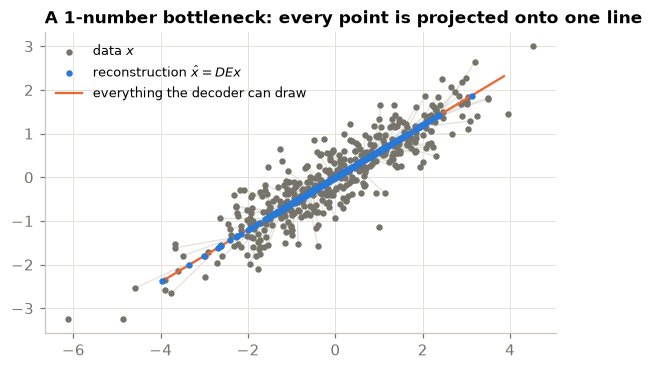

In [3]:
with torch.no_grad():
    rec = lin(Xc).numpy()
fig, ax = plt.subplots(figsize=(6, 3.6))
for p, r in zip(cloud[::2], rec[::2]):
    ax.plot([p[0], r[0]], [p[1], r[1]], color=HAIR, lw=0.8, zorder=1)
ax.scatter(*cloud.T, s=10, color=MUTED, label="data $x$", zorder=2)
ax.scatter(*rec.T, s=10, color=BLUE, label=r"reconstruction $\hat x = DEx$", zorder=3)
t = np.array([-4.5, 4.5])
ax.plot(t * direction[0], t * direction[1], color=ORANGE, lw=1.5, label="everything the decoder can draw", zorder=2)
ax.set_aspect("equal")
ax.set_title("A 1-number bottleneck: every point is projected onto one line", loc="left")
ax.legend(loc="upper left", fontsize=8.5)
plt.show()

### 2.2 A nonlinear autoencoder bends the line

Now the points lie on an arc. A linear AE can still only draw a straight line. Give the encoder and decoder hidden layers
with a nonlinearity (here `tanh`) and the decoder can draw a **curve** instead. The one-number code then becomes
"how far along the arc", a coordinate the network discovered by itself.

In [4]:
theta = rng.uniform(-2.3, 2.3, 400)                                    # position along the arc
arc = np.c_[np.cos(theta), np.sin(theta)] + rng.normal(scale=0.04, size=(400, 2))
arc -= arc.mean(0)
Xa = torch.tensor(arc, dtype=torch.float32)


class MLPAE(nn.Module):
    def __init__(self, d, k, h=32):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(d, h), nn.Tanh(), nn.Linear(h, h), nn.Tanh(), nn.Linear(h, k))
        self.decoder = nn.Sequential(nn.Linear(k, h), nn.Tanh(), nn.Linear(h, h), nn.Tanh(), nn.Linear(h, d))

    def forward(self, x):
        return self.decoder(self.encoder(x))


torch.manual_seed(0)
lin_arc = LinearAE(2, 1)
lin_arc_mse = train_full_batch(lin_arc, Xa)
torch.manual_seed(0)
mlp_arc = MLPAE(2, 1)
mlp_arc_mse = train_full_batch(mlp_arc, Xa, steps=4000, lr=3e-3)
print(f"linear AE MSE on the arc:    {lin_arc_mse:.4f}")
print(f"nonlinear AE MSE on the arc: {mlp_arc_mse:.4f}")

linear AE MSE on the arc:    0.1372
nonlinear AE MSE on the arc: 0.0009


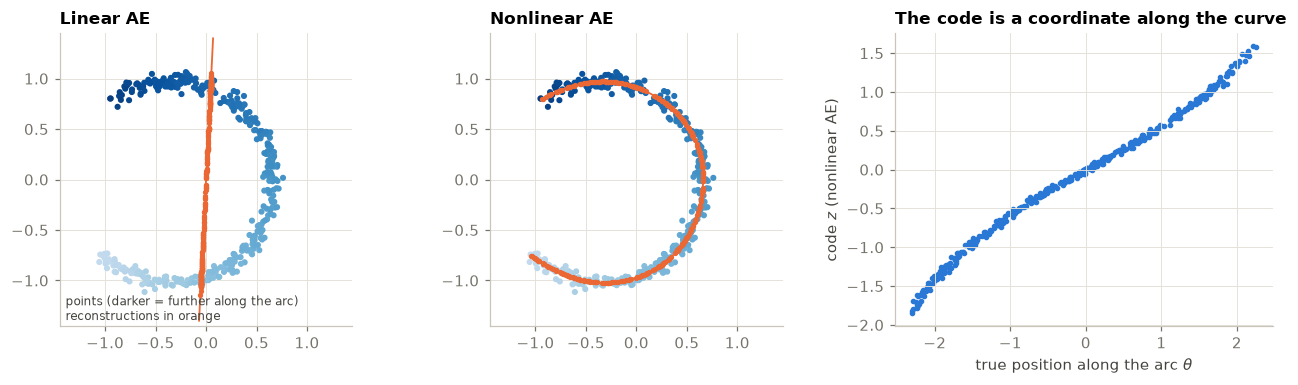

In [5]:
with torch.no_grad():
    rec_lin, rec_mlp = lin_arc(Xa).numpy(), mlp_arc(Xa).numpy()
    z_mlp = mlp_arc.encoder(Xa).numpy()[:, 0]
    zs = torch.linspace(z_mlp.min(), z_mlp.max(), 200)[:, None]
    curve = mlp_arc.decoder(zs).numpy()
    d_lin = lin_arc.D.weight.numpy()[:, 0]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for ax, rec_, title in [(axes[0], rec_lin, "Linear AE"), (axes[1], rec_mlp, "Nonlinear AE")]:
    ax.scatter(*arc.T, s=9, c=theta, cmap="Blues", vmin=-4, vmax=2.6, zorder=2)
    ax.scatter(*rec_.T, s=6, color=ORANGE, zorder=3)
    ax.set_aspect("equal")
    ax.set_title(title, loc="left")
for ax in axes[:2]:
    ax.set_xlim(-1.45, 1.45), ax.set_ylim(-1.45, 1.45)
t = np.linspace(-1.4, 1.4, 2)
axes[0].plot(t * d_lin[0] / np.linalg.norm(d_lin), t * d_lin[1] / np.linalg.norm(d_lin), color=ORANGE, lw=1.2)
axes[1].plot(*curve.T, color=ORANGE, lw=1.2)
axes[0].text(0.02, 0.02, "points (darker = further along the arc)\nreconstructions in orange", transform=axes[0].transAxes,
             fontsize=8, color=INK2)
axes[2].scatter(theta, z_mlp, s=7, color=BLUE)
axes[2].set_xlabel(r"true position along the arc $\theta$")
axes[2].set_ylabel("code $z$ (nonlinear AE)")
axes[2].set_title("The code is a coordinate along the curve", loc="left")
plt.tight_layout()
plt.show()

The code $z$ is a monotonic function of the true arc position $\theta$. The nonlinear AE has *unrolled* the curve onto a line.
This is the general picture behind every autoencoder: data that seems high-dimensional often lies near a lower-dimensional
surface (a *manifold*). The encoder learns coordinates on that surface and the decoder learns to draw it.

## 3. An autoencoder for handwritten digits

Each digit is an 8×8 image, so $x \in [0, 1]^{64}$. We squeeze it into **two** numbers, which is far too few for perfect
reconstructions but lets us plot every code.

* Encoder: 64 → 128 (ReLU) → 2. Decoder: 2 → 128 (ReLU) → 64 *logits*, turned into pixel intensities with a sigmoid.
* Loss: binary cross-entropy summed over the 64 pixels. Each pixel's intensity is treated as the probability that the pixel is "on".
  This is the usual choice for images in $[0, 1]$, and it is the same likelihood the VAE will use in section 5.

train (1437, 64), test (360, 64)


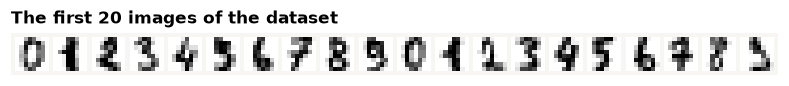

In [6]:
digits = load_digits()
X = (digits.data / 16.0).astype(np.float32)          # 1,797 images, 64 pixels each, scaled to [0, 1]
y = digits.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
Xtr, Xte, Xall = torch.from_numpy(X_tr), torch.from_numpy(X_te), torch.from_numpy(X)
print(f"train {X_tr.shape}, test {X_te.shape}")

fig, ax = plt.subplots(figsize=(9, 1.3))
show_mosaic(ax, X[:20], ncol=20, title="The first 20 images of the dataset")
plt.show()

In [7]:
H = 128


class AE(nn.Module):
    def __init__(self, k=2):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(64, H), nn.ReLU(), nn.Linear(H, k))
        self.decoder = nn.Sequential(nn.Linear(k, H), nn.ReLU(), nn.Linear(H, 64))   # outputs logits

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z


def bce(logits, x):
    """Binary cross-entropy summed over pixels, averaged over images."""
    return F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)


def ae_loss(model, x):
    return bce(model(x)[0], x)


def fit(model, loss_fn, epochs=300, lr=2e-3, bs=128, seed=0, X_train=None):
    """Mini-batch Adam. Returns the per-epoch (train, test) loss."""
    X_train = Xtr if X_train is None else X_train
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(X_train), generator=g)
        for i in range(0, len(perm), bs):
            loss = loss_fn(model, X_train[perm[i:i + bs]])
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            hist.append((loss_fn(model, X_train).item(), loss_fn(model, Xte).item()))
    return np.array(hist)


def pixel_mse(model, x):
    with torch.no_grad():
        return F.mse_loss(torch.sigmoid(model(x)[0]), x).item()


torch.manual_seed(0)
ae = AE(k=2)
hist_ae = fit(ae, ae_loss)
print(f"test BCE {hist_ae[-1, 1]:.2f} per image · test pixel MSE {pixel_mse(ae, Xte):.4f}")

test BCE 20.63 per image · test pixel MSE 0.0342


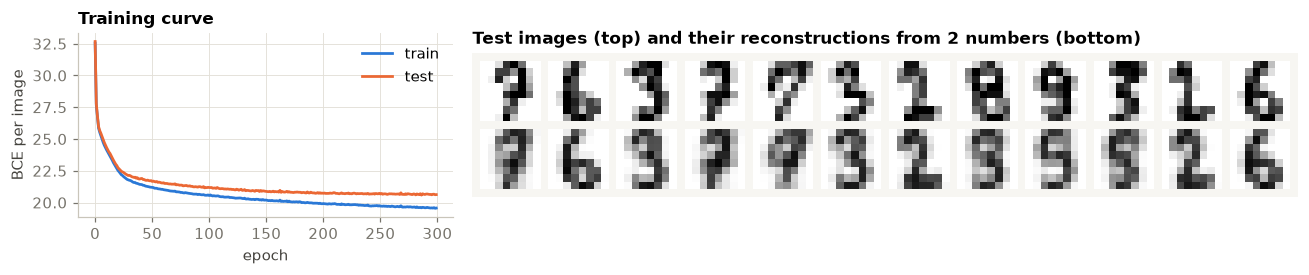

In [8]:
with torch.no_grad():
    rec_te = torch.sigmoid(ae(Xte)[0]).numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 2.6), gridspec_kw={"width_ratios": [1, 2.2]})
axes[0].plot(hist_ae[:, 0], label="train")
axes[0].plot(hist_ae[:, 1], label="test")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("BCE per image")
axes[0].set_title("Training curve", loc="left")
axes[0].legend()
show_mosaic(axes[1], np.concatenate([X_te[:12], rec_te[:12]]), ncol=12,
            title="Test images (top) and their reconstructions from 2 numbers (bottom)")
plt.tight_layout()
plt.show()

Two numbers keep the overall shape of each digit but lose the details. Now look at the codes themselves: each of the
1,797 images becomes one point in the plane, drawn as its own digit.

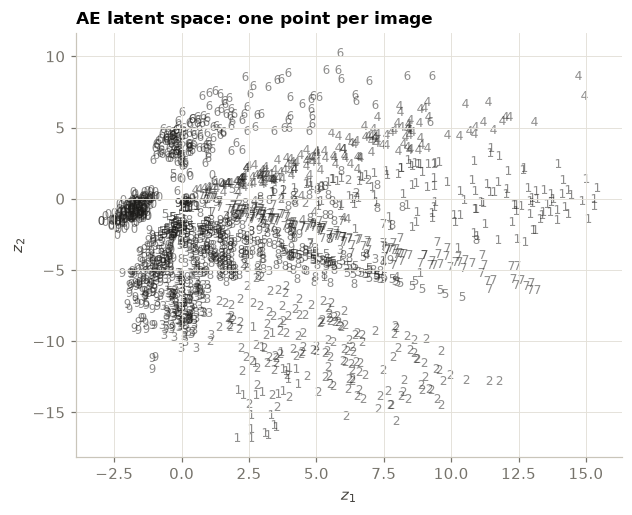

In [9]:
with torch.no_grad():
    Z_ae = ae.encoder(Xall).numpy()
fig, ax = plt.subplots(figsize=(6.4, 5))
glyph_scatter(ax, Z_ae, y)
ax.set_xlabel("$z_1$")
ax.set_ylabel("$z_2$")
ax.set_title("AE latent space: one point per image", loc="left")
plt.show()

Without ever seeing a label, the encoder has sorted the images by shape: each digit occupies its own region, and digits that
look alike (3, 5, 8, 9) sit next to each other.

**How small can the bottleneck be?** Compare the nonlinear AE with PCA (the best *linear* code) for a few code sizes $k$:

k= 2  PCA 0.0532  AE 0.0342


k= 4  PCA 0.0379  AE 0.0209


k= 8  PCA 0.0246  AE 0.0117


k=16  PCA 0.0116  AE 0.0058


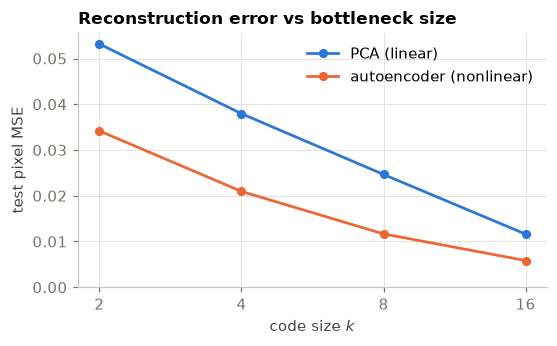

In [10]:
ks = [2, 4, 8, 16]
mse_pca, mse_ae = [], []
for k in ks:
    p = PCA(k).fit(X_tr)
    mse_pca.append(((p.inverse_transform(p.transform(X_te)) - X_te) ** 2).mean())
    torch.manual_seed(0)
    m = AE(k)
    fit(m, ae_loss)
    mse_ae.append(pixel_mse(m, Xte))
    print(f"k={k:2d}  PCA {mse_pca[-1]:.4f}  AE {mse_ae[-1]:.4f}")

fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(ks, mse_pca, marker="o", ms=5, label="PCA (linear)")
ax.plot(ks, mse_ae, marker="o", ms=5, label="autoencoder (nonlinear)")
ax.set_xscale("log", base=2)
ax.set_xticks(ks, [str(k) for k in ks])
ax.set_xlabel("code size $k$")
ax.set_ylabel("test pixel MSE")
ax.set_ylim(0, None)
ax.set_title("Reconstruction error vs bottleneck size", loc="left")
ax.legend()
plt.show()

At every size the nonlinear AE rebuilds the digits with one half to two thirds of PCA's error. A curved surface fits the data better
than a flat one, just as with the arc.

## 4. Why a plain autoencoder is not a generator

The decoder turns *any* two numbers into an image. So can we create new digits by picking a random point and decoding it?
Decode a regular grid of points across the region the codes occupy:

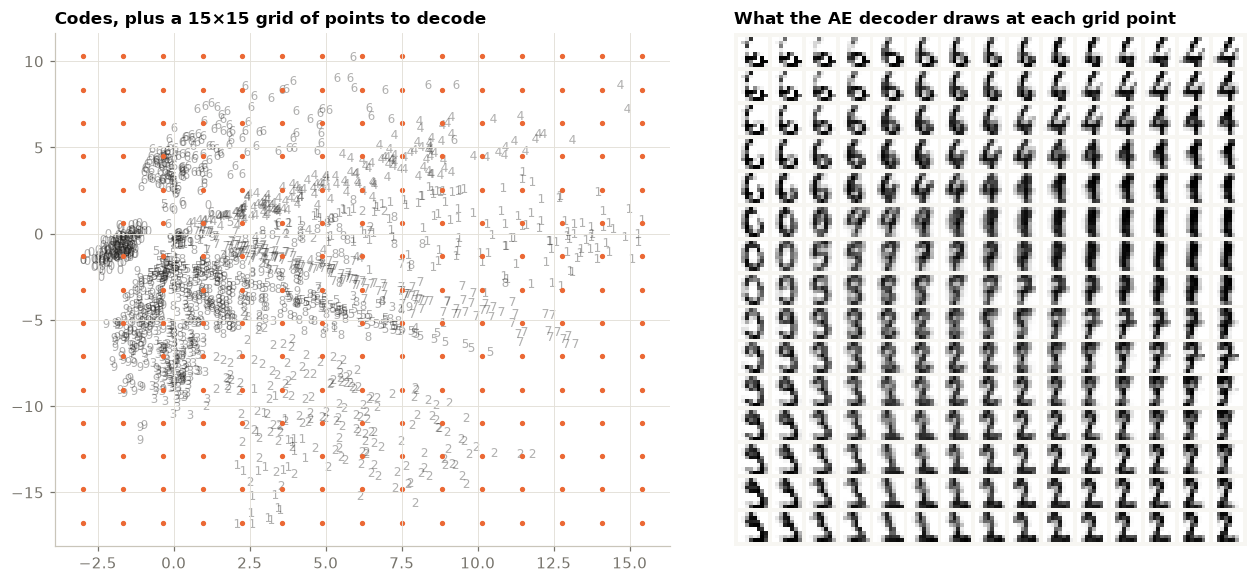

In [11]:
def decode_grid(model, xlim, ylim, n=15):
    gx, gy = np.linspace(*xlim, n), np.linspace(*ylim, n)[::-1]          # top row = largest z2
    grid = np.array([[a, b] for b in gy for a in gx], dtype=np.float32)
    with torch.no_grad():
        imgs = torch.sigmoid(model.decoder(torch.from_numpy(grid))).numpy()
    return grid, imgs


lo, hi = Z_ae.min(0), Z_ae.max(0)
grid_ae, imgs_ae = decode_grid(ae, (lo[0], hi[0]), (lo[1], hi[1]))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
glyph_scatter(axes[0], Z_ae, y, alpha=0.35)
axes[0].scatter(*grid_ae.T, s=6, color=ORANGE)
axes[0].set_title("Codes, plus a 15×15 grid of points to decode", loc="left")
show_mosaic(axes[1], imgs_ae, ncol=15, title="What the AE decoder draws at each grid point")
plt.tight_layout()
plt.show()

On a dataset this small the decoder extrapolates gracefully: almost every grid point still decodes to something digit-like,
with a few hybrids along the borders. The problems are about the **layout** of the code space:

* **No scale, no center.** The codes span roughly −3…15 by −17…10. Another training run would put them somewhere else.
  Nothing tells us which distribution to draw $z$ from.
* **Uneven territory.** The loss only cares that each image's code decodes well, not how much room each kind of image gets.
  Measure it: draw points uniformly in the box and ask which digit owns the nearest training code.
* **Empty regions are unconstrained.** No code ever landed there, so whatever the decoder draws is an accident of extrapolation.
  That happens to be benign here, but on richer data (faces, sounds) it usually is not.

In [12]:
def territory(codes, z_samples):
    """Share of sampled latent points whose nearest training code belongs to each digit."""
    nearest = KNeighborsClassifier(n_neighbors=1).fit(codes, y).predict(z_samples)
    return np.bincount(nearest, minlength=10) / len(z_samples)


g = np.random.default_rng(0)
z_box = g.uniform(lo, hi, size=(4000, 2)).astype(np.float32)
share_ae = territory(Z_ae, z_box)
print("share of the AE's box owned by each digit:")
print("  ".join(f"{d}: {s:.0%}" for d, s in enumerate(share_ae)))

share of the AE's box owned by each digit:
0: 3%  1: 16%  2: 24%  3: 3%  4: 12%  5: 4%  6: 18%  7: 9%  8: 4%  9: 7%


## 5. The variational autoencoder

Kingma & Welling (2014) and Rezende et al. (2014) fixed this by making the autoencoder a proper probabilistic model.

**The generative story.** Draw a code from a fixed prior, then draw an image from the decoder:

$$ z \sim p(z) = \mathcal{N}(0, I), \qquad x \sim p_\theta(x \mid z) = \prod_{j=1}^{64} \mathrm{Bernoulli}\big(x_j;\ \sigma(g_\theta(z))_j\big). $$

If we can fit this model, generating new data is trivial: sample $z \sim \mathcal{N}(0, I)$ and decode.

**The obstacle.** Fitting means maximizing $\log p_\theta(x) = \log \int p_\theta(x\mid z)\,p(z)\,dz$, an integral over every possible code,
with no closed form.

**The trick.** Bring in an encoder that proposes, for each $x$, a small Gaussian cloud of plausible codes:
$q_\phi(z \mid x) = \mathcal{N}\big(\mu_\phi(x), \operatorname{diag}\sigma_\phi^2(x)\big)$. For any such $q$,

$$ \log p_\theta(x) \;=\; \underbrace{\mathbb{E}_{q_\phi(z\mid x)}\big[\log p_\theta(x \mid z)\big] \;-\; \mathrm{KL}\big(q_\phi(z\mid x)\,\|\,p(z)\big)}_{\text{ELBO (evidence lower bound)}} \;+\; \underbrace{\mathrm{KL}\big(q_\phi(z\mid x)\,\|\,p_\theta(z\mid x)\big)}_{\ge 0}. $$

The last term is never negative, so the ELBO is a lower bound on $\log p_\theta(x)$. Maximizing it over $\theta$ and $\phi$ fits the model
and makes $q$ close to the true posterior. The loss is the negative ELBO, and it has two readable parts:

$$ \mathcal{L}(x) = \underbrace{-\,\mathbb{E}_{q}\big[\log p_\theta(x\mid z)\big]}_{\text{reconstruction (BCE)}} \;+\; \beta\,\underbrace{\tfrac12 \sum_{j=1}^{k}\big(\mu_j^2 + \sigma_j^2 - \ln \sigma_j^2 - 1\big)}_{\mathrm{KL}(q\,\|\,\mathcal{N}(0,I)) \text{ in closed form}}, \qquad \beta = 1. $$

* The **reconstruction** term is the AE's loss, now with the code drawn from the encoder's cloud instead of being a single point.
* The **KL** term pulls every cloud towards $\mathcal{N}(0, I)$: means towards 0, widths towards 1. It is zero only if the code carries no
  information about $x$, so the two terms pull in opposite directions.

**The reparameterization trick.** Backpropagation can't go through "sample $z$ from $\mathcal{N}(\mu, \sigma^2)$". Rewrite the sample as a
deterministic function of $(\mu, \sigma)$ and outside noise:

$$ z = \mu_\phi(x) + \sigma_\phi(x) \odot \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, I). $$

Now $\partial z / \partial \mu = 1$ and $\partial z / \partial \sigma = \varepsilon$, and gradients flow into the encoder.
Compared with the AE, the code changes in three lines: the encoder outputs $2k$ numbers $(\mu, \log\sigma^2)$, we add noise, and we add the KL term.

In [13]:
class VAE(nn.Module):
    def __init__(self, k=2):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(64, H), nn.ReLU(), nn.Linear(H, 2 * k))   # -> [mu, log sigma^2]
        self.decoder = nn.Sequential(nn.Linear(k, H), nn.ReLU(), nn.Linear(H, 64))

    def encode(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=-1)
        return mu, logvar

    def forward(self, x):
        mu, logvar = self.encode(x)
        eps = torch.randn_like(mu)
        z = mu + eps * torch.exp(0.5 * logvar)          # reparameterization trick
        return self.decoder(z), mu, logvar


def kl_to_std_normal(mu, logvar):
    return 0.5 * (mu.pow(2) + logvar.exp() - logvar - 1).sum(-1)


def vae_terms(model, x):
    logits, mu, logvar = model(x)
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(-1)
    return rec.mean(), kl_to_std_normal(mu, logvar).mean()


def vae_loss(model, x, beta=1.0):
    rec, kl = vae_terms(model, x)
    return rec + beta * kl

A quick sanity check of the closed-form KL against a Monte Carlo estimate $\mathbb{E}_{z\sim q}[\log q(z) - \log p(z)]$:

In [14]:
mu_t, logvar_t = torch.tensor([0.8, -0.3]), torch.tensor([-1.0, 0.4])
q = torch.distributions.Normal(mu_t, torch.exp(0.5 * logvar_t))
prior = torch.distributions.Normal(0.0, 1.0)
z = q.sample((200_000,))
mc = (q.log_prob(z) - prior.log_prob(z)).sum(-1).mean()
print(f"closed form {kl_to_std_normal(mu_t, logvar_t).item():.4f}   Monte Carlo {mc.item():.4f}")

closed form 0.5949   Monte Carlo 0.5952


In [15]:
torch.manual_seed(0)
vae = VAE(k=2)
hist_vae = fit(vae, vae_loss)
vae.eval()
with torch.no_grad():
    rec_vae, kl_vae = vae_terms(vae, Xte)
    mu_all, logvar_all = vae.encode(Xall)
    mu_all, sigma_all = mu_all.numpy(), torch.exp(0.5 * logvar_all).numpy()
    vae_pix = F.mse_loss(torch.sigmoid(vae.decoder(vae.encode(Xte)[0])), Xte).item()
print(f"VAE test: reconstruction {rec_vae:.2f} + KL {kl_vae:.2f} = {rec_vae + kl_vae:.2f} nats per image (negative ELBO)")
print(f"pixel MSE decoding the mean code: VAE {vae_pix:.4f} vs AE {pixel_mse(ae, Xte):.4f}")
print(f"average encoder sigma: {sigma_all.mean():.3f}")

VAE test: reconstruction 21.81 + KL 2.58 = 24.39 nats per image (negative ELBO)
pixel MSE decoding the mean code: VAE 0.0360 vs AE 0.0342
average encoder sigma: 0.293


Reconstructions are almost as good as the AE's. The latent space is very different, though:

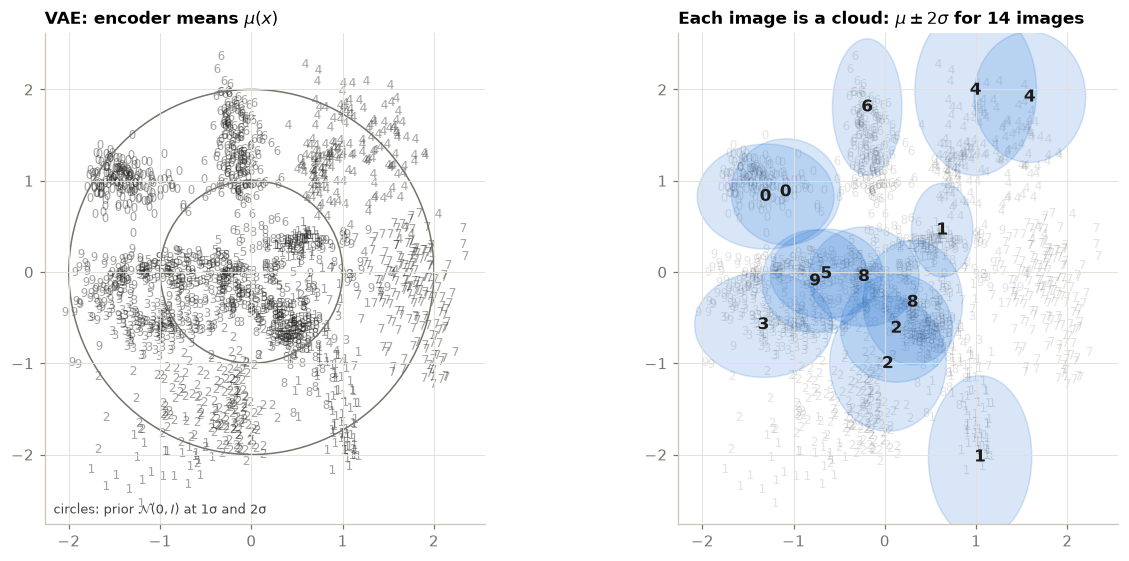

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
glyph_scatter(axes[0], mu_all, y, alpha=0.4)
for r in (1, 2):
    axes[0].add_patch(Circle((0, 0), r, fill=False, color=MUTED, lw=1))
axes[0].text(0.02, 0.02, r"circles: prior $\mathcal{N}(0, I)$ at 1σ and 2σ", transform=axes[0].transAxes, color=INK2, fontsize=8.5)
axes[0].set_aspect("equal")
axes[0].set_title(r"VAE: encoder means $\mu(x)$", loc="left")

pick = np.random.default_rng(3).choice(len(X), 14, replace=False)
glyph_scatter(axes[1], mu_all, y, alpha=0.12)
for i in pick:
    axes[1].add_patch(Ellipse(mu_all[i], 4 * sigma_all[i, 0], 4 * sigma_all[i, 1], fill=True,
                              facecolor=BLUE, alpha=0.18, edgecolor=BLUE, lw=1))
    axes[1].text(*mu_all[i], str(y[i]), ha="center", va="center", fontsize=11, weight="bold", color=INK)
axes[1].set_xlim(axes[0].get_xlim()), axes[1].set_ylim(axes[0].get_ylim())
axes[1].set_aspect("equal")
axes[1].set_title(r"Each image is a cloud: $\mu \pm 2\sigma$ for 14 images", loc="left")
plt.tight_layout()
plt.show()

The KL term has packed all codes into the prior's disk (roughly radius 2.5, compared with a span of about 30 for the AE), and each
image is now an ellipse rather than a point. The decoder had to decode *every* point of those overlapping ellipses during
training, so there is no unclaimed space between the clusters. Decode the same kind of grid as before, over $[-2.5, 2.5]^2$:

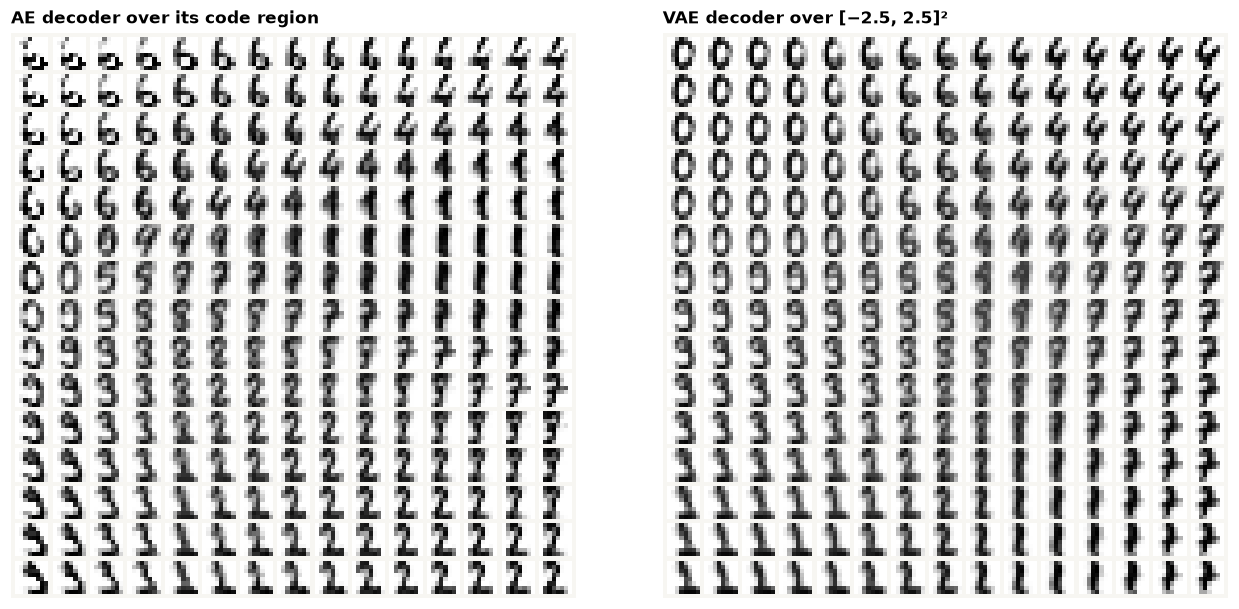

In [17]:
grid_vae, imgs_vae = decode_grid(vae, (-2.5, 2.5), (-2.5, 2.5))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
show_mosaic(axes[0], imgs_ae, ncol=15, title="AE decoder over its code region")
show_mosaic(axes[1], imgs_vae, ncol=15, title="VAE decoder over [−2.5, 2.5]²")
plt.tight_layout()
plt.show()

Two differences stand out. The VAE's map is **balanced**: every digit gets a patch of comparable size, where the AE gave whole rows
to 1s, 2s and 6s. And it is **blurrier**: neighbouring ellipses overlap, so the decoder learns to average between them.

Measure both. *Territory*: sample the prior and ask which digit owns the nearest code. This is the same test as for the AE's box.
*Sharpness*: decode samples and count how many a simple digit classifier (logistic regression, about 97% test accuracy) labels with
more than 90% confidence. The AE gets two samplers: uniform in its box, and a Gaussian fitted to its codes after training.

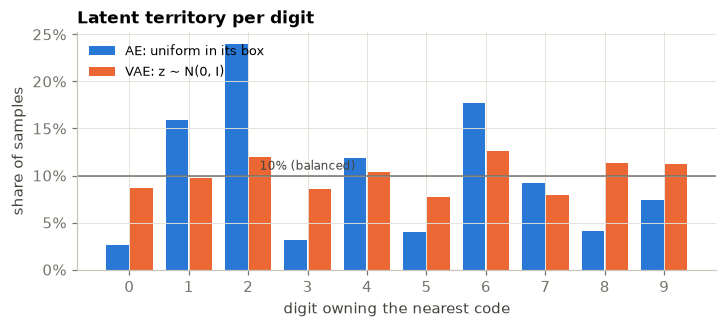

classifier test accuracy: 96.7%
AE, z uniform in its box                   confidently classified: 58%
AE, z from a Gaussian fitted to its codes  confidently classified: 39%
VAE, z ~ N(0, I)                           confidently classified: 31%
reference: real test images                confidently classified: 72%


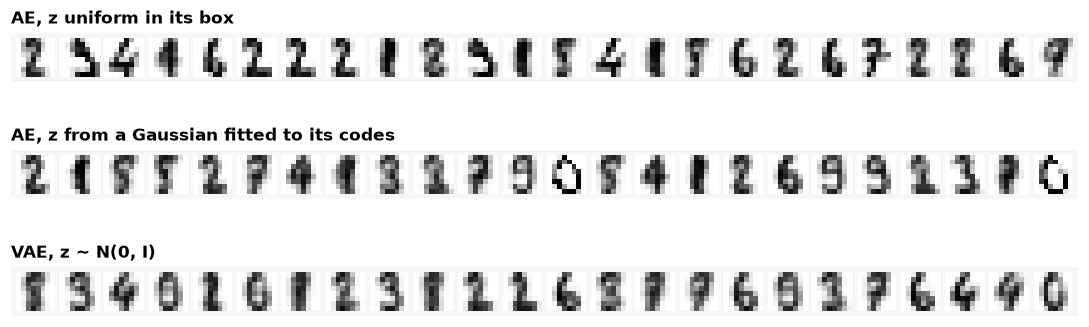

In [18]:
z_pri = g.normal(size=(4000, 2)).astype(np.float32)
share_vae = territory(mu_all, z_pri)

fig, ax = plt.subplots(figsize=(7.5, 2.8))
xs = np.arange(10)
ax.bar(xs - 0.2, share_ae, width=0.38, color=BLUE, label="AE: uniform in its box")
ax.bar(xs + 0.2, share_vae, width=0.38, color=ORANGE, label="VAE: z ~ N(0, I)")
ax.axhline(0.1, color=MUTED, lw=1)
ax.text(3, 0.103, "10% (balanced)", ha="center", va="bottom", fontsize=8, color=INK2)
ax.set_xticks(xs, [str(d) for d in xs])
ax.set_xlabel("digit owning the nearest code")
ax.set_ylabel("share of samples")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Latent territory per digit", loc="left")
ax.legend(loc="upper left", fontsize=8.5)
plt.show()

clf = LogisticRegression(max_iter=3000).fit(X_tr, y_tr)
print(f"classifier test accuracy: {clf.score(X_te, y_te):.1%}")
z_fit = g.multivariate_normal(Z_ae.mean(0), np.cov(Z_ae.T), size=4000).astype(np.float32)
with torch.no_grad():
    samples = {
        "AE, z uniform in its box": torch.sigmoid(ae.decoder(torch.from_numpy(z_box))).numpy(),
        "AE, z from a Gaussian fitted to its codes": torch.sigmoid(ae.decoder(torch.from_numpy(z_fit))).numpy(),
        "VAE, z ~ N(0, I)": torch.sigmoid(vae.decoder(torch.from_numpy(z_pri))).numpy(),
    }
samples_real = X_te
for name, s in list(samples.items()) + [("reference: real test images", samples_real)]:
    print(f"{name:42s} confidently classified: {np.mean(clf.predict_proba(s).max(1) > 0.9):.0%}")

fig, axes = plt.subplots(3, 1, figsize=(10, 3.6))
for ax, (name, s) in zip(axes, samples.items()):
    show_mosaic(ax, s[:24], ncol=24, title=name)
plt.tight_layout()
plt.show()

The numbers make the trade-off explicit:

* Under the VAE's prior every digit owns close to 10% of the territory. Under the AE's box, a few digits own most of it and
  others almost none.
* The AE's samples are sharper: more of them are classified confidently. The VAE pays for its regular latent space with blur.
* On 2-D digits, a Gaussian fitted to the AE's codes after training is a reasonable patch. But it is a second model fitted
  afterwards, and in higher dimensions the codes rarely look Gaussian. The VAE builds the prior into training, and adds a likelihood
  bound (the ELBO) and a per-input uncertainty $\sigma(x)$ that the AE does not have.

Finally, walk in a straight line between the codes of two test images and decode along the way:

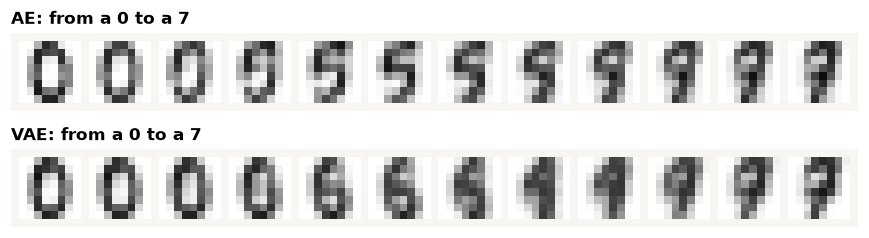

In [19]:
def interpolate(model, a, b, steps=10, vae_model=False):
    with torch.no_grad():
        za = model.encode(a[None])[0] if vae_model else model.encoder(a[None])
        zb = model.encode(b[None])[0] if vae_model else model.encoder(b[None])
        t = torch.linspace(0, 1, steps)[:, None]
        return torch.sigmoid(model.decoder((1 - t) * za + t * zb)).numpy()


ia, ib = np.where(y_te == 0)[0][0], np.where(y_te == 7)[0][0]
fig, axes = plt.subplots(2, 1, figsize=(8, 2.4))
show_mosaic(axes[0], interpolate(ae, Xte[ia], Xte[ib], 12), ncol=12, title="AE: from a 0 to a 7")
show_mosaic(axes[1], interpolate(vae, Xte[ia], Xte[ib], 12, vae_model=True), ncol=12, title="VAE: from a 0 to a 7")
plt.tight_layout()
plt.show()

Both paths pass through other digits (the AE through 5 and 9, the VAE through 6 and 4), because a straight line in a 2-D code space
crosses other digits' territory. The VAE's frames change more evenly, since its codes are spread out more evenly.

## 6. The β knob: reconstruction vs a regular latent space

The weight $\beta$ on the KL term sets the trade-off (Higgins et al., 2017, called the model with $\beta > 1$ a *β-VAE*):

* **small β**: the KL barely matters, codes spread out, reconstructions are sharp, and the model drifts back towards a plain AE;
* **large β**: codes are squeezed onto the prior, reconstructions blur;
* **too large β**: the cheapest solution is to ignore $x$ entirely. Every $q(z\mid x)$ collapses onto the prior (KL = 0) and the
  decoder outputs one average digit. This failure is called **posterior collapse**.

In [20]:
betas = [0.1, 1.0, 2.0, 4.0]
beta_models = {}
for b in betas:
    torch.manual_seed(0)
    m = VAE(k=2)
    fit(m, lambda mod, x, b=b: vae_loss(mod, x, beta=b))
    m.eval()
    with torch.no_grad():
        rec_b, kl_b = vae_terms(m, Xte)
        mse_b = F.mse_loss(torch.sigmoid(m.decoder(m.encode(Xte)[0])), Xte).item()
    beta_models[b] = m
    print(f"beta={b:<4} reconstruction {rec_b:6.2f}  KL {kl_b:5.2f}  pixel MSE {mse_b:.4f}")

beta=0.1  reconstruction  21.10  KL  5.92  pixel MSE 0.0367


beta=1.0  reconstruction  21.81  KL  2.58  pixel MSE 0.0360


beta=2.0  reconstruction  24.07  KL  1.20  pixel MSE 0.0459


beta=4.0  reconstruction  27.20  KL  0.00  pixel MSE 0.0740


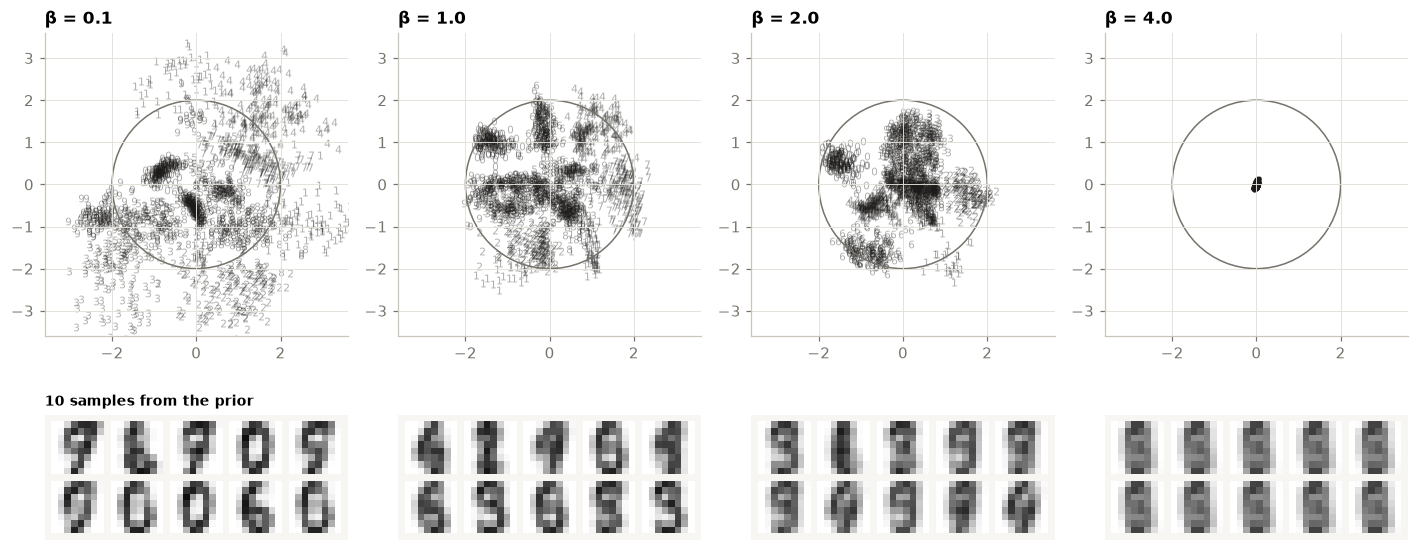

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.4), gridspec_kw={"height_ratios": [3, 1]})
zp = torch.from_numpy(np.random.default_rng(1).normal(size=(10, 2)).astype(np.float32))
for j, b in enumerate(betas):
    m = beta_models[b]
    with torch.no_grad():
        mu_b = m.encode(Xall)[0].numpy()
        samples = torch.sigmoid(m.decoder(zp)).numpy()
    glyph_scatter(axes[0, j], mu_b, y, alpha=0.35, size=26)
    axes[0, j].add_patch(Circle((0, 0), 2, fill=False, color=MUTED, lw=1))
    axes[0, j].set_xlim(-3.6, 3.6), axes[0, j].set_ylim(-3.6, 3.6)
    axes[0, j].set_aspect("equal")
    axes[0, j].set_title(f"β = {b}", loc="left")
    show_mosaic(axes[1, j], samples, ncol=5)
axes[1, 0].set_title("10 samples from the prior", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

At β = 4 every code sits at the origin and all ten samples are the same blurry "average digit": posterior collapse.
Collapse is a real risk whenever the decoder can do well without the code. In the next notebook it shapes how a VAE forecaster
is built.

## 7. Two uses that carry over to time series

### 7.1 Denoising autoencoder

Corrupt the input but keep the clean image as the target (Vincent et al., 2008). The AE can no longer copy its input, so it has
to learn what digits look like in order to remove the noise.

MSE to the clean image: noisy input 0.0668 · plain AE 0.0775 · denoising AE 0.0213


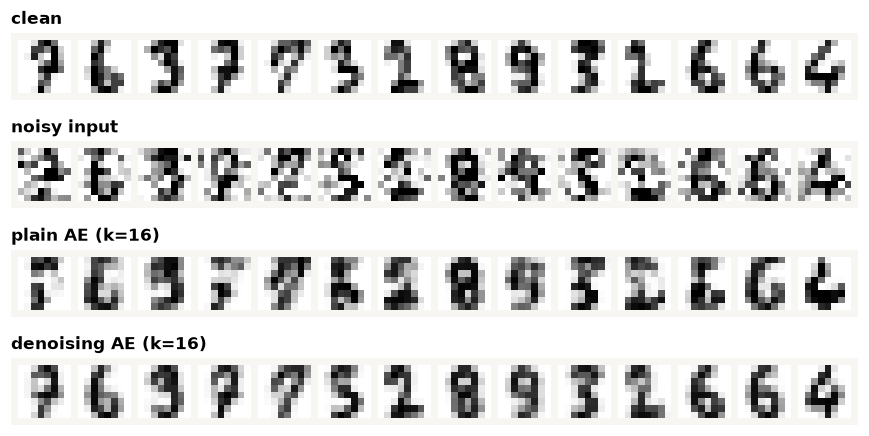

In [22]:
def dae_loss(model, x, noise=0.35):
    x_noisy = (x + noise * torch.randn_like(x)).clamp(0, 1)
    return bce(model(x_noisy)[0], x)


torch.manual_seed(0)
dae = AE(k=16)
fit(dae, dae_loss)
torch.manual_seed(0)
plain16 = AE(k=16)
fit(plain16, ae_loss)

torch.manual_seed(5)
x_noisy = (Xte + 0.35 * torch.randn_like(Xte)).clamp(0, 1)
with torch.no_grad():
    out_plain = torch.sigmoid(plain16(x_noisy)[0])
    out_dae = torch.sigmoid(dae(x_noisy)[0])
print(f"MSE to the clean image: noisy input {F.mse_loss(x_noisy, Xte):.4f} · plain AE {F.mse_loss(out_plain, Xte):.4f} "
      f"· denoising AE {F.mse_loss(out_dae, Xte):.4f}")
fig, axes = plt.subplots(4, 1, figsize=(8, 4.2))
for ax, imgs, name in zip(axes, [Xte, x_noisy, out_plain, out_dae],
                          ["clean", "noisy input", "plain AE (k=16)", "denoising AE (k=16)"]):
    show_mosaic(ax, imgs[:14].numpy(), ncol=14, title=name)
plt.tight_layout()
plt.show()

### 7.2 Anomaly detection by reconstruction error

An AE rebuilds well only what resembles its training data. Train it on every digit **except 7**, then score each test image by its
reconstruction error. The 7s, which the model has never seen, should score high. The same recipe on sliding windows of a sensor
signal is one of the most common time-series anomaly detectors. The paper discussed in the next notebook calls for revisiting
Transformer-based solutions for that task too.

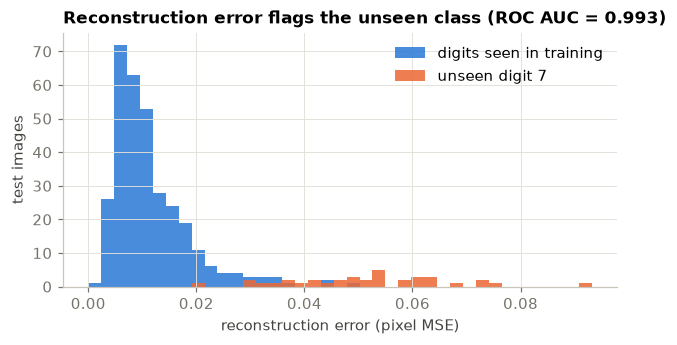

In [23]:
held_out = 7
torch.manual_seed(0)
ae_no7 = AE(k=8)
fit(ae_no7, ae_loss, X_train=torch.from_numpy(X_tr[y_tr != held_out]))
with torch.no_grad():
    err = ((torch.sigmoid(ae_no7(Xte)[0]) - Xte) ** 2).mean(1).numpy()
is_anomaly = (y_te == held_out)
auc = roc_auc_score(is_anomaly, err)

fig, ax = plt.subplots(figsize=(6.5, 3))
bins = np.linspace(0, err.max(), 40)
ax.hist(err[~is_anomaly], bins=bins, color=BLUE, alpha=0.85, label="digits seen in training")
ax.hist(err[is_anomaly], bins=bins, color=ORANGE, alpha=0.85, label=f"unseen digit {held_out}")
ax.set_xlabel("reconstruction error (pixel MSE)")
ax.set_ylabel("test images")
ax.set_title(f"Reconstruction error flags the unseen class (ROC AUC = {auc:.3f})", loc="left")
ax.legend()
plt.show()

## 8. Summary

| | Autoencoder | Variational autoencoder |
|---|---|---|
| Encoder output | a code $z = f_\phi(x)$ | a distribution $q_\phi(z\mid x) = \mathcal{N}(\mu, \sigma^2)$ |
| Loss | reconstruction | reconstruction + β · KL to the prior (negative ELBO) |
| Latent space | wherever training puts it, with holes | packed around $\mathcal{N}(0, I)$, continuous |
| Generates new data? | not reliably | yes: $z \sim \mathcal{N}(0, I)$, decode |
| Typical uses | compression, features, denoising, anomaly detection | generation, uncertainty, smooth interpolation |
| Failure mode | memorizing details, holes in the code space | blur; posterior collapse when β is too large |

**Next:** [02 · Autoencoders for time-series forecasting](02_autoencoders_for_time_series_forecasting.ipynb) applies these ideas to
forecasting. It reads them through *Are Transformers Effective for Time Series Forecasting?* (Zeng et al., AAAI 2023).

### References

* P. Baldi, K. Hornik. *Neural networks and principal component analysis: learning from examples without local minima.* Neural Networks, 1989.
* G. E. Hinton, R. R. Salakhutdinov. *Reducing the dimensionality of data with neural networks.* Science, 2006.
* P. Vincent, H. Larochelle, Y. Bengio, P.-A. Manzagol. *Extracting and composing robust features with denoising autoencoders.* ICML 2008.
* D. P. Kingma, M. Welling. *Auto-Encoding Variational Bayes.* ICLR 2014. [arXiv:1312.6114](https://arxiv.org/abs/1312.6114)
* D. J. Rezende, S. Mohamed, D. Wierstra. *Stochastic backpropagation and approximate inference in deep generative models.* ICML 2014.
* I. Higgins et al. *β-VAE: Learning basic visual concepts with a constrained variational framework.* ICLR 2017.